In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)

In [4]:
DATA_DIR = Path("../data/raw")

telemetry = pd.read_csv(
    DATA_DIR / "points_with_jobs_tele_ult.csv"
)

failures = pd.read_csv(
    DATA_DIR / "failures.csv"
)

locations = pd.read_csv(
    DATA_DIR / "locations_by_serials.csv"
)

C:\Users\KARAN\AppData\Local\Temp\ipykernel_23924\115821359.py:3: DtypeWarning: Columns (85) have mixed types. Specify dtype option on import or set low_memory=False.
  telemetry = pd.read_csv(


In [5]:
print("Telemetry:", telemetry.shape)
print("Failures:", failures.shape)
print("Locations:", locations.shape)

Telemetry: (50259, 150)
Failures: (3154866, 6)
Locations: (60271, 7)


In [6]:
telemetry.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50259 entries, 0 to 50258
Columns: 150 entries, timestamp to mem_temp_range_1min
dtypes: float64(123), int64(10), object(17)
memory usage: 57.5+ MB


In [7]:
telemetry.head()

,timestamp,hostname,GPU,serial,is_failure,prev_xid48,next_xid48,hours_in_job,allocation_id,user_name,account,gpu_energy,gpu_usage,flag_gpumps,flag_gpudefault,flag_smt1,flag_smt2,flag_smt4,flag_nvme,flag_cpublink,flag_disableautonuma,flag_isolategpfs,flag_maximizegpfs,n_jobs_1h,jobhours_1h,n_jobs_6h,jobhours_6h,n_jobs_24h,jobhours_24h,n_jobs_120h,jobhours_120h,job_max_power,job_range_power,job_min_power,n_no_tele_6h,n_no_tele_1h,n_no_tele_15min,n_no_tele_5min,n_no_tele_1min,n_NA_power_6h,n_NA_core_temp_6h,n_NA_mem_temp_6h,n_NA_power_1h,n_NA_core_temp_1h,n_NA_mem_temp_1h,n_NA_power_15min,n_NA_core_temp_15min,n_NA_mem_temp_15min,n_NA_power_5min,n_NA_core_temp_5min,n_NA_mem_temp_5min,n_NA_power_1min,n_NA_core_temp_1min,n_NA_mem_temp_1min,power_fluct_6h,core_temp_fluct_6h,mem_temp_fluct_6h,power_fluct_1h,core_temp_fluct_1h,mem_temp_fluct_1h,power_fluct_15min,core_temp_fluct_15min,mem_temp_fluct_15min,power_fluct_5min,core_temp_fluct_5min,mem_temp_fluct_5min,power_fluct_1min,core_temp_fluct_1min,mem_temp_fluct_1min,power_fluct_lifetime,core_temp_fluct_lifetime,mem_temp_fluct_lifetime,power_avg_lifetime,core_temp_avg_lifetime,mem_temp_avg_lifetime,power_min_lifetime,power_max_lifetime,power_range_lifetime,core_temp_min_lifetime,core_temp_max_lifetime,core_temp_range_lifetime,mem_temp_min_lifetime,mem_temp_max_lifetime,mem_temp_range_lifetime,n_zero_power,last_zero_power,n_zero_core_temp,last_zero_core_temp,n_zero_mem_temp,last_zero_mem_temp,power_mean_6h,power_min_6h,power_max_6h,power_range_6h,core_temp_mean_6h,core_temp_min_6h,core_temp_max_6h,core_temp_range_6h,mem_temp_mean_6h,mem_temp_min_6h,mem_temp_max_6h,mem_temp_range_6h,power_mean_1h,power_min_1h,power_max_1h,power_range_1h,core_temp_mean_1h,core_temp_min_1h,core_temp_max_1h,core_temp_range_1h,mem_temp_mean_1h,mem_temp_min_1h,mem_temp_max_1h,mem_temp_range_1h,power_mean_15min,power_min_15min,power_max_15min,power_range_15min,core_temp_mean_15min,core_temp_min_15min,core_temp_max_15min,core_temp_range_15min,mem_temp_mean_15min,mem_temp_min_15min,mem_temp_max_15min,mem_temp_range_15min,power_mean_5min,power_min_5min,power_max_5min,power_range_5min,core_temp_mean_5min,core_temp_min_5min,core_temp_max_5min,core_temp_range_5min,mem_temp_mean_5min,mem_temp_min_5min,mem_temp_max_5min,mem_temp_range_5min,power_mean_1min,power_min_1min,power_max_1min,power_range_1min,core_temp_mean_1min,core_temp_min_1min,core_temp_max_1min,core_temp_range_1min,mem_temp_mean_1min,mem_temp_min_1min,mem_temp_max_1min,mem_temp_range_1min
0,2020-10-05 15:22:36+00:00,a06n13,3,323817128720,0,NaN,NaN,0.990875,1431524.0,3964fb85353cda6319ee40094e447c3cc842b57d9e1725...,96520f52939a9005a2f723752d246aa8c355f22c849542...,4200815.0,0.000000e+00,True,False,False,False,False,False,False,False,False,False,2,0.995367,5,5.973337,7,23.955706,56,119.066958,35.0,2.0,33.0,2023.0,340.0,88.0,28.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.000512,0.058937,0.125505,0.239123,0.006509,0.011990,0.226833,0.000000,0.000000,0.185185,0.000000,0.000000,0.117647,0.000000,0.000000,17.620121,0.180033,0.319890,77.229276,32.989384,30.052375,10.0,419.0,409.0,24.0,53.0,29.0,21.0,56.0,35.0,0,NaN,0,NaN,0,NaN,47.320172,33.0,367.0,334.0,29.894468,28.0,37.0,9.0,26.618277,25.0,36.0,11.0,33.200920,33.0,48.0,15.0,29.955521,29.0,31.0,2.0,26.936810,25.0,28.0,3.0,33.181034,33.0,35.0,2.0,30.000000,30.0,30.0,0.0,27.000000,27.0,27.0,0.0,33.147059,33.0,34.0,1.0,30.000000,30.0,30.0,0.0,27.000000,27.0,27.0,0.0,33.071429,33.0,34.0,1.0,30.000000,30.0,30.0,0.0,27.000000,27.0,27.0,0.0
1,2020-10-05 06:41:43+00:00,a07n13,3,323917105722,0,NaN,NaN,3.322851,1430887.0,fb80684aa48268896c159222c220515678b54ea6732db4...,29748b20d0924aba9d64fcfb7c9e50afd2e5ec0ebbb830...,8288790.0,0.000000e+00,False,False,False,False,False,False,False,False,False,False,1,1.000000,2,5.991718,5,23.964134,44,119.207576,79.0,45.0,34.0,1929.0,314.0,76.0,30.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.371020,0.008454,0.035901,0.382442,0.000000,0.0

In [8]:
telemetry.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,50259,50242,2021-09-05 01:44:22+00:00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hostname,50259,4733,f24n16,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GPU,50259.0,NaN,NaN,NaN,2.501761,1.70833,0.0,1.0,2.0,4.0,5.0
serial,50259.0,NaN,NaN,NaN,349979715303.133423,168181679680.3255,320118104014.0,323717010540.0,324117099213.0,324417122458.5,1564919006835.0
is_failure,50259.0,NaN,NaN,NaN,0.00587,0.076389,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
core_temp_range_1min,33768.0,NaN,NaN,NaN,1.5487,2.515484,0.0,0.0,1.0,2.0,26.0
mem_temp_mean_1min,32915.0,NaN,NaN,NaN,32.061655,6.23901,23.0,27.981132,30.0,34.590939,83.0
mem_temp_min_1min,32915.0,NaN,NaN,NaN,30.936716,5.386227,23.0,27.0,29.0,33.0,83.0
mem_temp_max_1min,32915.0,NaN,NaN,NaN,33.291919,6.974749,23.0,28.0,31.0,37.0,83.0


In [9]:
telemetry.columns.tolist()

['timestamp',
 'hostname',
 'GPU',
 'serial',
 'is_failure',
 'prev_xid48',
 'next_xid48',
 'hours_in_job',
 'allocation_id',
 'user_name',
 'account',
 'gpu_energy',
 'gpu_usage',
 'flag_gpumps',
 'flag_gpudefault',
 'flag_smt1',
 'flag_smt2',
 'flag_smt4',
 'flag_nvme',
 'flag_cpublink',
 'flag_disableautonuma',
 'flag_isolategpfs',
 'flag_maximizegpfs',
 'n_jobs_1h',
 'jobhours_1h',
 'n_jobs_6h',
 'jobhours_6h',
 'n_jobs_24h',
 'jobhours_24h',
 'n_jobs_120h',
 'jobhours_120h',
 'job_max_power',
 'job_range_power',
 'job_min_power',
 'n_no_tele_6h',
 'n_no_tele_1h',
 'n_no_tele_15min',
 'n_no_tele_5min',
 'n_no_tele_1min',
 'n_NA_power_6h',
 'n_NA_core_temp_6h',
 'n_NA_mem_temp_6h',
 'n_NA_power_1h',
 'n_NA_core_temp_1h',
 'n_NA_mem_temp_1h',
 'n_NA_power_15min',
 'n_NA_core_temp_15min',
 'n_NA_mem_temp_15min',
 'n_NA_power_5min',
 'n_NA_core_temp_5min',
 'n_NA_mem_temp_5min',
 'n_NA_power_1min',
 'n_NA_core_temp_1min',
 'n_NA_mem_temp_1min',
 'power_fluct_6h',
 'core_temp_fluct_6h',

In [10]:
telemetry["is_failure"].value_counts()

is_failure
0    49964
1      295
Name: count, dtype: int64

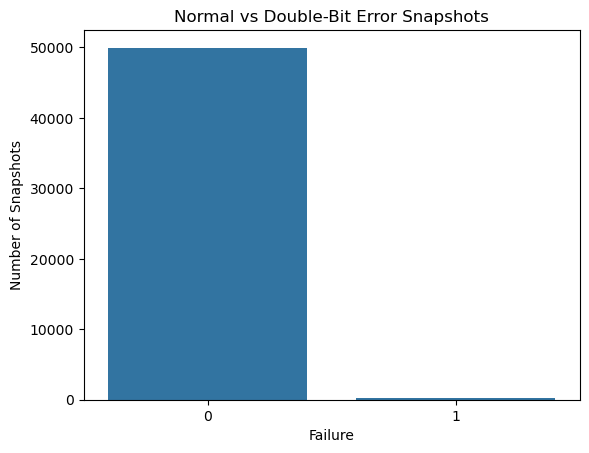

In [11]:
sns.countplot(data=telemetry, x="is_failure")

plt.title("Normal vs Double-Bit Error Snapshots")
plt.xlabel("Failure")
plt.ylabel("Number of Snapshots")
plt.show()

In [12]:
failures.head()

,timestamp,hostname,GPU,PCI,xid,message
0,2022-02-19T23:32:18-05:00,h22n02,5.0,0035:05:00,31,"NVRM: Xid (PCI:0035:05:00): 31, pid=2629696, ..."
1,2022-02-19T23:32:15-05:00,h25n14,1.0,0004:05:00,31,"NVRM: Xid (PCI:0004:05:00): 31, pid=344194, C..."
2,2022-02-19T23:32:13-05:00,h22n09,0.0,0004:04:00,31,"NVRM: Xid (PCI:0004:04:00): 31, pid=2696639, ..."
3,2022-02-19T23:32:12-05:00,h22n04,0.0,0004:04:00,31,"NVRM: Xid (PCI:0004:04:00): 31, pid=2318979, ..."
4,2022-02-19T23:32:11-05:00,h23n04,3.0,0035:03:00,31,"NVRM: Xid (PCI:0035:03:00): 31, pid=375622, C..."


In [13]:
failures["xid"].value_counts()

xid
13    1816535
31     708756
92     531326
43      42923
64      41527
74       9414
63       1829
48       1088
45        704
44        230
61        206
79        129
32         66
62         58
38         52
12         21
0           1
69          1
Name: count, dtype: int64

In [14]:
failures["xid"].nunique()

18

In [15]:
failures["xid"].unique()

array([31, 64, 63, 13, 43, 92, 79, 48, 62, 44, 38, 61, 74, 45, 32, 12,  0,
       69])

In [16]:
telemetry["serial"].nunique()

23520

In [17]:
telemetry["hostname"].nunique()

4733

In [18]:
failure_gpus = (
    telemetry[telemetry["is_failure"] == 1]
    ["serial"]
    .value_counts()
)

failure_gpus.head(20)

serial
325217016964     31
1321620038124    24
320118104517     14
324117100228     12
324417122534     12
323817128029     12
323117073681      9
1320120065982     8
1321620038152     7
325217017806      7
561419003719      5
323117106178      5
324517039533      5
324017016656      5
323117073725      5
324117101315      5
323017124776      4
561419005249      4
325217015901      4
325117196719      4
Name: count, dtype: int64

In [19]:
[c for c in telemetry.columns if "temp" in c.lower()]

['n_NA_core_temp_6h',
 'n_NA_mem_temp_6h',
 'n_NA_core_temp_1h',
 'n_NA_mem_temp_1h',
 'n_NA_core_temp_15min',
 'n_NA_mem_temp_15min',
 'n_NA_core_temp_5min',
 'n_NA_mem_temp_5min',
 'n_NA_core_temp_1min',
 'n_NA_mem_temp_1min',
 'core_temp_fluct_6h',
 'mem_temp_fluct_6h',
 'core_temp_fluct_1h',
 'mem_temp_fluct_1h',
 'core_temp_fluct_15min',
 'mem_temp_fluct_15min',
 'core_temp_fluct_5min',
 'mem_temp_fluct_5min',
 'core_temp_fluct_1min',
 'mem_temp_fluct_1min',
 'core_temp_fluct_lifetime',
 'mem_temp_fluct_lifetime',
 'core_temp_avg_lifetime',
 'mem_temp_avg_lifetime',
 'core_temp_min_lifetime',
 'core_temp_max_lifetime',
 'core_temp_range_lifetime',
 'mem_temp_min_lifetime',
 'mem_temp_max_lifetime',
 'mem_temp_range_lifetime',
 'n_zero_core_temp',
 'last_zero_core_temp',
 'n_zero_mem_temp',
 'last_zero_mem_temp',
 'core_temp_mean_6h',
 'core_temp_min_6h',
 'core_temp_max_6h',
 'core_temp_range_6h',
 'mem_temp_mean_6h',
 'mem_temp_min_6h',
 'mem_temp_max_6h',
 'mem_temp_range_6h',
 

In [20]:
telemetry.groupby("is_failure")[
    ["core_temp_mean_1h", "mem_temp_mean_1h"]
].mean()

,core_temp_mean_1h,mem_temp_mean_1h
is_failure,,
0,33.621878,32.049965
1,33.943471,33.135156


In [21]:
print("Telemetry:", telemetry.shape)
print("Failures:", failures.shape)
print("Locations:", locations.shape)

print(telemetry["is_failure"].value_counts())
print(failures["xid"].value_counts())

print(telemetry["serial"].nunique())
print(telemetry["hostname"].nunique())

Telemetry: (50259, 150)
Failures: (3154866, 6)
Locations: (60271, 7)
is_failure
0    49964
1      295
Name: count, dtype: int64
xid
13    1816535
31     708756
92     531326
43      42923
64      41527
74       9414
63       1829
48       1088
45        704
44        230
61        206
79        129
32         66
62         58
38         52
12         21
0           1
69          1
Name: count, dtype: int64
23520
4733


In [22]:
dbe = failures[failures["xid"] == 48].copy()

print("XID 48 records:", len(dbe))
print("Unique timestamps:", dbe["timestamp"].nunique())
print("Unique PCI:", dbe["PCI"].nunique())

dbe["timestamp"] = pd.to_datetime(dbe["timestamp"])

print("Earliest DBE:", dbe["timestamp"].min())
print("Latest DBE:", dbe["timestamp"].max())

print(
    "Duplicates:",
    dbe.duplicated(
        subset=["timestamp", "hostname", "GPU", "PCI"]
    ).sum()
)

print(locations.columns.tolist())
print(locations.dtypes)
print(locations.head())

XID 48 records: 1088
Unique timestamps: 382
Unique PCI: 6
Earliest DBE: 2019-12-02 02:44:06-05:00
Latest DBE: 2022-09-21 21:00:29-04:00
Duplicates: 706
['start', 'end', 'serial', 'hostname', 'GPU', 'model', 'bus']
start       object
end         object
serial       int64
hostname    object
GPU          int64
model       object
bus         object
dtype: object
                              start                               end  \
0         2019-01-01 00:00:00-05:00  2021-08-18 01:01:55.583292-04:00   
1  2021-08-18 01:01:55.583292-04:00         2099-01-01 00:00:00-05:00   
2         2019-01-01 00:00:00-05:00  2021-08-18 01:01:55.583292-04:00   
3  2021-08-18 01:01:55.583292-04:00         2099-01-01 00:00:00-05:00   
4         2019-01-01 00:00:00-05:00  2021-08-18 01:01:55.583292-04:00   

         serial hostname  GPU                 model               bus  
0  323717010659   a01n01    0                   NaN  00000004:04:00.0  
1  323717010659   a01n01    0  Tesla V100-SXM2-16GB  000

C:\Users\KARAN\AppData\Local\Temp\ipykernel_23924\431295167.py:7: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  dbe["timestamp"] = pd.to_datetime(dbe["timestamp"])


In [24]:
locations["start"] = pd.to_datetime(
    locations["start"],
    format="mixed",
    errors="coerce"
)

locations["end"] = pd.to_datetime(
    locations["end"],
    format="mixed",
    errors="coerce"
)

print(locations.dtypes)
print(locations[["start", "end"]].head())

start       object
end         object
serial       int64
hostname    object
GPU          int64
model       object
bus         object
dtype: object
                              start                               end
0         2019-01-01 00:00:00-05:00  2021-08-18 01:01:55.583292-04:00
1  2021-08-18 01:01:55.583292-04:00         2099-01-01 00:00:00-05:00
2         2019-01-01 00:00:00-05:00  2021-08-18 01:01:55.583292-04:00
3  2021-08-18 01:01:55.583292-04:00         2099-01-01 00:00:00-05:00
4         2019-01-01 00:00:00-05:00  2021-08-18 01:01:55.583292-04:00


C:\Users\KARAN\AppData\Local\Temp\ipykernel_23924\1439267181.py:1: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  locations["start"] = pd.to_datetime(
C:\Users\KARAN\AppData\Local\Temp\ipykernel_23924\1439267181.py:7: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  locations["end"] = pd.to_datetime(


In [25]:
dbe["timestamp"] = pd.to_datetime(dbe["timestamp"])

print(dbe["timestamp"].dtype)

ValueError: Tz-aware datetime.datetime cannot be converted to datetime64 unless utc=True, at position 31

In [26]:
dbe_unique = dbe.drop_duplicates(
    subset=["timestamp", "hostname", "GPU", "PCI"]
).copy()

print("Original XID-48 records:", len(dbe))
print("Unique DBE events:", len(dbe_unique))

Original XID-48 records: 1088
Unique DBE events: 382


In [27]:
print("DBE hostname examples:")
print(dbe_unique["hostname"].head())

print("\nLocation hostname examples:")
print(locations["hostname"].head())

print("\nDBE PCI examples:")
print(dbe_unique["PCI"].head())

print("\nLocation bus examples:")
print(locations["bus"].head())

DBE hostname examples:
24080    h29n04
24394    g08n11
28162    a20n10
28170    a20n10
36617    h29n04
Name: hostname, dtype: object

Location hostname examples:
0    a01n01
1    a01n01
2    a01n01
3    a01n01
4    a01n01
Name: hostname, dtype: object

DBE PCI examples:
24080    0035:03:00
24394    0035:05:00
28162    0004:04:00
28170    0004:04:00
36617    0035:03:00
Name: PCI, dtype: object

Location bus examples:
0    00000004:04:00.0
1    00000004:04:00.0
2    00000004:05:00.0
3    00000004:05:00.0
4    00000004:06:00.0
Name: bus, dtype: object


In [28]:
print(
    "DBE PCI count:",
    dbe_unique["PCI"].nunique()
)

print(
    "Location bus count:",
    locations["bus"].nunique()
)

DBE PCI count: 6
Location bus count: 10


In [29]:
print(
    dbe_unique["PCI"].unique()
)

print(
    locations["bus"].unique()[:10]
)

['0035:03:00' '0035:05:00' '0004:04:00' '0035:04:00' '0004:05:00'
 '0004:06:00']
['00000004:04:00.0' '00000004:05:00.0' '00000004:06:00.0'
 '00000035:03:00.0' '00000035:04:00.0' '00000035:05:00.0'
 '00000004:09:00.0' '00000004:0A:00.0' '00000035:08:00.0'
 '00000035:09:00.0']


In [30]:
# STEP 4 — Map DBE events to GPU serials

# Keep only XID 48 events
dbe = failures[failures["xid"] == 48].copy()

# Remove duplicate records belonging to the same DBE event
dbe_unique = dbe.drop_duplicates(
    subset=["timestamp", "hostname", "GPU", "PCI"]
).copy()

# Convert timestamps
dbe_unique["timestamp"] = pd.to_datetime(
    dbe_unique["timestamp"],
    utc=True,
    format="mixed"
)

locations["start"] = pd.to_datetime(
    locations["start"],
    utc=True,
    format="mixed"
)

locations["end"] = pd.to_datetime(
    locations["end"],
    utc=True,
    format="mixed"
)

# Normalize GPU IDs
dbe_unique["GPU"] = pd.to_numeric(dbe_unique["GPU"], errors="coerce")
locations["GPU"] = pd.to_numeric(locations["GPU"], errors="coerce")

# Normalize PCI/BUS format
def normalize_pci(x):
    if pd.isna(x):
        return None

    x = str(x).strip()

    # Remove leading zeros from first PCI component
    parts = x.split(":")

    if len(parts) == 3:
        parts[0] = parts[0].lstrip("0") or "0"

        # Location bus contains .0, failure PCI usually doesn't
        if "." not in parts[-1]:
            parts[-1] = parts[-1] + ".0"

        return ":".join(parts)

    return x


dbe_unique["pci_norm"] = dbe_unique["PCI"].apply(normalize_pci)
locations["pci_norm"] = locations["bus"].apply(normalize_pci)

# Merge on hostname + GPU + PCI
mapped = dbe_unique.merge(
    locations[
        ["start", "end", "serial", "hostname", "GPU", "pci_norm"]
    ],
    on=["hostname", "GPU", "pci_norm"],
    how="left"
)

# Keep only the location interval containing the failure
mapped = mapped[
    (mapped["timestamp"] >= mapped["start"]) &
    (mapped["timestamp"] < mapped["end"])
].copy()

print("Unique XID-48 events:", len(dbe_unique))
print("Successfully mapped events:", len(mapped))
print("Unmapped events:", len(dbe_unique) - len(mapped))

Unique XID-48 events: 382
Successfully mapped events: 357
Unmapped events: 25


In [31]:
mapped[
    ["timestamp", "hostname", "GPU", "PCI", "serial"]
].head(20)

,timestamp,hostname,GPU,PCI,serial
1,2022-02-14 13:07:52+00:00,h29n04,3.0,0035:03:00,3.251172e+11
3,2022-02-14 05:09:56+00:00,g08n11,5.0,0035:05:00,3.244171e+11
5,2022-02-13 01:05:10+00:00,a20n10,0.0,0004:04:00,3.233171e+11
7,2022-02-13 01:05:02+00:00,a20n10,0.0,0004:04:00,3.233171e+11
9,2022-02-11 19:04:18+00:00,h29n04,3.0,0035:03:00,3.251172e+11
11,2022-02-11 12:13:21+00:00,h29n04,3.0,0035:03:00,3.251172e+11
13,2022-02-10 19:44:19+00:00,h29n04,3.0,0035:03:00,3.251172e+11
15,2022-02-10 05:15:52+00:00,f07n03,4.0,0035:04:00,3.245170e+11
17,2022-02-09 02:49:41+00:00,b06n07,3.0,0035:03:00,3.241171e+11
19,2022-02-06 20:05:31+00:00,h28n16,1.0,0004:05:00,3.252170e+11


In [34]:
print("Unique GPU serials involved:", mapped["serial"].nunique())
print("Unique hosts involved:", mapped["hostname"].nunique())

print("\nUnmapped host/GPU combinations:")
unmapped_keys = dbe_unique.merge(
    mapped[["timestamp", "hostname", "GPU", "PCI"]],
    on=["timestamp", "hostname", "GPU", "PCI"],
    how="left",
    indicator=True
)

print(
    unmapped_keys[
        unmapped_keys["_merge"] == "left_only"
    ][["hostname", "GPU", "PCI"]]
    .drop_duplicates()
    .head(30)
)

Unique GPU serials involved: 124
Unique hosts involved: 120

Unmapped host/GPU combinations:
   hostname  GPU         PCI
18   login1  3.0  0035:03:00


In [35]:
import pandas as pd

points = pd.read_csv("../data/raw/points_with_jobs_tele_ult.csv")

print(points.shape)
print(points.head())
print(points.columns.tolist())

(50259, 150)
                   timestamp hostname  GPU        serial  is_failure  \
0  2020-10-05 15:22:36+00:00   a06n13    3  323817128720           0   
1  2020-10-05 06:41:43+00:00   a07n13    3  323917105722           0   
2  2020-10-05 02:35:48+00:00   a13n13    1  323917104670           0   
3  2020-10-05 20:20:53+00:00   a15n01    5  323817128633           0   
4  2020-10-05 02:14:04+00:00   a17n09    3  323417016503           0   

   prev_xid48  next_xid48  hours_in_job  allocation_id  \
0         NaN         NaN      0.990875      1431524.0   
1         NaN         NaN      3.322851      1430887.0   
2         NaN         NaN      4.917025      1430510.0   
3         NaN         NaN      4.248692      1431750.0   
4         NaN         NaN      4.554803      1430510.0   

                                           user_name  \
0  3964fb85353cda6319ee40094e447c3cc842b57d9e1725...   
1  fb80684aa48268896c159222c220515678b54ea6732db4...   
2  572a2ac7ebc881b5c36342e3cb3112b965

C:\Users\KARAN\AppData\Local\Temp\ipykernel_23924\2680721830.py:3: DtypeWarning: Columns (85) have mixed types. Specify dtype option on import or set low_memory=False.
  points = pd.read_csv("../data/raw/points_with_jobs_tele_ult.csv")


In [36]:
points["timestamp"] = pd.to_datetime(
    points["timestamp"],
    utc=True,
    format="mixed"
)

check = mapped.merge(
    points[["timestamp", "serial", "is_failure"]],
    on=["timestamp", "serial"],
    how="left"
)

print("Mapped DBE events:", len(mapped))
print("Matched in points dataset:", check["is_failure"].notna().sum())
print("Not matched:", check["is_failure"].isna().sum())

print("\nMatched failure labels:")
print(check["is_failure"].value_counts(dropna=False))

Mapped DBE events: 357
Matched in points dataset: 295
Not matched: 62

Matched failure labels:
is_failure
1.0    295
NaN     62
Name: count, dtype: int64


In [37]:
print(points["is_failure"].value_counts())
print()
print(points["is_failure"].value_counts(normalize=True) * 100)


is_failure
0    49964
1      295
Name: count, dtype: int64

is_failure
0    99.41304
1     0.58696
Name: proportion, dtype: float64


In [38]:
print(points.columns.tolist())

['timestamp', 'hostname', 'GPU', 'serial', 'is_failure', 'prev_xid48', 'next_xid48', 'hours_in_job', 'allocation_id', 'user_name', 'account', 'gpu_energy', 'gpu_usage', 'flag_gpumps', 'flag_gpudefault', 'flag_smt1', 'flag_smt2', 'flag_smt4', 'flag_nvme', 'flag_cpublink', 'flag_disableautonuma', 'flag_isolategpfs', 'flag_maximizegpfs', 'n_jobs_1h', 'jobhours_1h', 'n_jobs_6h', 'jobhours_6h', 'n_jobs_24h', 'jobhours_24h', 'n_jobs_120h', 'jobhours_120h', 'job_max_power', 'job_range_power', 'job_min_power', 'n_no_tele_6h', 'n_no_tele_1h', 'n_no_tele_15min', 'n_no_tele_5min', 'n_no_tele_1min', 'n_NA_power_6h', 'n_NA_core_temp_6h', 'n_NA_mem_temp_6h', 'n_NA_power_1h', 'n_NA_core_temp_1h', 'n_NA_mem_temp_1h', 'n_NA_power_15min', 'n_NA_core_temp_15min', 'n_NA_mem_temp_15min', 'n_NA_power_5min', 'n_NA_core_temp_5min', 'n_NA_mem_temp_5min', 'n_NA_power_1min', 'n_NA_core_temp_1min', 'n_NA_mem_temp_1min', 'power_fluct_6h', 'core_temp_fluct_6h', 'mem_temp_fluct_6h', 'power_fluct_1h', 'core_temp_fluc

In [39]:
DROP_COLS = [
    "is_failure",      # target
    "prev_xid48",      # leakage
    "next_xid48",      # leakage
    "timestamp",       # handle time separately
    "hostname",        # identifier
    "serial",          # identifier
    "GPU",             # identifier
    "allocation_id",
    "user_name",
    "account"
]

In [40]:
X = points.drop(columns=DROP_COLS)

print("Features:", X.shape[1])

print("\nMissing values:")
print(X.isna().sum().sort_values(ascending=False).head(20))

print("\nConstant columns:")
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]
print(constant_cols)

Features: 140

Missing values:
last_zero_power         50240
last_zero_core_temp     49848
last_zero_mem_temp      49833
flag_gpumps             20913
flag_nvme               20913
flag_cpublink           20913
flag_disableautonuma    20913
flag_smt4               20913
flag_isolategpfs        20913
flag_smt2               20913
flag_smt1               20913
flag_gpudefault         20913
flag_maximizegpfs       20913
mem_temp_fluct_1min     17450
mem_temp_fluct_5min     17353
mem_temp_range_1min     17344
mem_temp_min_1min       17344
mem_temp_mean_1min      17344
mem_temp_max_1min       17344
mem_temp_range_5min     17334
dtype: int64

Constant columns:
[]


In [42]:
import pandas as pd
from sklearn.impute import SimpleImputer

# Check data types
print(X.dtypes)

# Convert timestamp column to datetime
if "timestamp" in X.columns:
    X["timestamp"] = pd.to_datetime(
        X["timestamp"],
        errors="coerce",
        format="mixed"
    )

    # Create useful time-based features
    X["year"] = X["timestamp"].dt.year
    X["month"] = X["timestamp"].dt.month
    X["day"] = X["timestamp"].dt.day
    X["hour"] = X["timestamp"].dt.hour
    X["day_of_week"] = X["timestamp"].dt.dayofweek

    # Remove original timestamp
    X = X.drop(columns=["timestamp"])

# Keep only numeric columns
X = X.select_dtypes(include=["number"])

# Median imputation
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

print("Original shape:", X.shape)
print("After imputation:", X_imputed.shape)

hours_in_job            float64
gpu_energy              float64
gpu_usage               float64
flag_gpumps              object
flag_gpudefault          object
                         ...   
core_temp_range_1min    float64
mem_temp_mean_1min      float64
mem_temp_min_1min       float64
mem_temp_max_1min       float64
mem_temp_range_1min     float64
Length: 140, dtype: object
Original shape: (50259, 127)
After imputation: (50259, 127)


In [43]:
# Check the non-numeric columns
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("Categorical columns:", len(categorical_cols))
print(categorical_cols)

print("\nUnique values:")
for col in categorical_cols:
    print(col, "->", X[col].dropna().unique()[:10])

Categorical columns: 0
[]

Unique values:


In [44]:
y = points["is_failure"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

print("\nFailure rate:", y.mean())

X shape: (50259, 127)
y shape: (50259,)

Class distribution:
is_failure
0    49964
1      295
Name: count, dtype: int64

Failure rate: 0.005869595495334169


In [45]:
# Sort chronologically
points_sorted = points.sort_values("timestamp").reset_index(drop=True)

# 80% train, 20% test
split_idx = int(len(points_sorted) * 0.80)

train = points_sorted.iloc[:split_idx]
test = points_sorted.iloc[split_idx:]

X_train = train.drop(columns=DROP_COLS)
X_test = test.drop(columns=DROP_COLS)

y_train = train["is_failure"].astype(int)
y_test = test["is_failure"].astype(int)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

print("\nTrain failures:", y_train.sum())
print("Test failures :", y_test.sum())

print("\nTrain period:")
print(train["timestamp"].min(), "→", train["timestamp"].max())

print("\nTest period:")
print(test["timestamp"].min(), "→", test["timestamp"].max())

Train: (40207, 140)
Test : (10052, 140)

Train failures: 241
Test failures : 54

Train period:
2019-12-31 00:15:19+00:00 → 2021-11-24 18:15:39+00:00

Test period:
2021-11-24 19:22:39+00:00 → 2022-05-17 22:17:13+00:00


In [46]:
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score

# Impute using TRAINING data only
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

# Handle class imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("scale_pos_weight:", scale_pos_weight)

# Baseline XGBoost
model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_imp, y_train)

# Predictions
y_prob = model.predict_proba(X_test_imp)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("ROC-AUC :", roc_auc_score(y_test, y_prob))
print("PR-AUC  :", average_precision_score(y_test, y_prob))

ModuleNotFoundError: No module named 'xgboost'

In [47]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 3.9 MB/s eta 0:00:13
   - -------------------------------------- 1.6/48.9 MB 4.1 MB/s eta 0:00:12
   -- ------------------------------------- 2.6/48.9 MB 4.3 MB/s eta 0:00:11
   -- ------------------------------------- 3.4/48.9 MB 4.2 MB/s eta 0:00:11
   --- ------------------------------------ 4.2/48.9 MB 4.0 MB/s eta 0:00:12
   ---- ----------------------------------- 5.0/48.9 MB 3.9 MB/s eta 0:00:12
   ---- ----------------------------------- 5.8/48.9 MB 3.9 MB/s eta 0:00:12
   ----- ---------------------------------- 6.6/48.9 MB 3.9 MB/s eta 0:00:11
   ----- ---------------------------------- 7.3/48.9 MB 4.0 MB/s eta 0:00:11
   ------ --------------------------------- 8.4/48.9 MB 4.0 MB/s eta 0:00:11
   ------- -------------------------------- 9.4/48.9 MB 4.0 MB/s eta 0:00:10
   -------- ------------------------------- 10.2/48.9 MB 4.0 MB/s eta 0:00:10
   --

In [50]:
import pandas as pd
from sklearn.impute import SimpleImputer

# Check which columns are non-numeric
print("Non-numeric columns:")
print(X_train.select_dtypes(exclude="number").columns.tolist())

# Convert timestamp to useful numerical features
for df in [X_train, X_test]:
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(
            df["timestamp"],
            errors="coerce",
            format="mixed"
        )

        df["year"] = df["timestamp"].dt.year
        df["month"] = df["timestamp"].dt.month
        df["day"] = df["timestamp"].dt.day
        df["hour"] = df["timestamp"].dt.hour
        df["day_of_week"] = df["timestamp"].dt.dayofweek

        df.drop(columns=["timestamp"], inplace=True)

# Keep only numeric features
X_train = X_train.select_dtypes(include="number")
X_test = X_test.select_dtypes(include="number")

# Make sure train and test have exactly the same columns
X_test = X_test.reindex(columns=X_train.columns)

# Impute using TRAINING data only
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("After imputation:", X_train_imp.shape)

Non-numeric columns:
['flag_gpumps', 'flag_gpudefault', 'flag_smt1', 'flag_smt2', 'flag_smt4', 'flag_nvme', 'flag_cpublink', 'flag_disableautonuma', 'flag_isolategpfs', 'flag_maximizegpfs', 'last_zero_power', 'last_zero_core_temp', 'last_zero_mem_temp']
Training shape: (40207, 127)
Test shape: (10052, 127)
After imputation: (40207, 127)


In [51]:
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score

# Impute using TRAINING data only
imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

# Handle class imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("scale_pos_weight:", scale_pos_weight)

# Baseline XGBoost
model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_imp, y_train)

# Predictions
y_prob = model.predict_proba(X_test_imp)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("ROC-AUC :", roc_auc_score(y_test, y_prob))
print("PR-AUC  :", average_precision_score(y_test, y_prob))

scale_pos_weight: 165.83402489626556

Classification Report:
              precision    recall  f1-score   support

           0     0.9966    0.9949    0.9957      9998
           1     0.2817    0.3704    0.3200        54

    accuracy                         0.9915     10052
   macro avg     0.6391    0.6826    0.6579     10052
weighted avg     0.9928    0.9915    0.9921     10052

ROC-AUC : 0.8665270091055248
PR-AUC  : 0.32114467161026783


In [52]:
import numpy as np

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    pred = (y_prob >= threshold).astype(int)

    from sklearn.metrics import precision_score, recall_score, f1_score

    print(
        f"Threshold={threshold:.2f} | "
        f"Precision={precision_score(y_test, pred, zero_division=0):.3f} | "
        f"Recall={recall_score(y_test, pred):.3f} | "
        f"F1={f1_score(y_test, pred):.3f} | "
        f"Alerts={pred.sum()}"
    )

Threshold=0.10 | Precision=0.042 | Recall=0.630 | F1=0.078 | Alerts=818
Threshold=0.20 | Precision=0.087 | Recall=0.556 | F1=0.151 | Alerts=343
Threshold=0.30 | Precision=0.174 | Recall=0.556 | F1=0.265 | Alerts=172
Threshold=0.40 | Precision=0.208 | Recall=0.407 | F1=0.275 | Alerts=106
Threshold=0.50 | Precision=0.282 | Recall=0.370 | F1=0.320 | Alerts=71


In [53]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print(feature_importance.head(20).to_string(index=False))

               feature  importance
         n_NA_power_6h    0.051054
   core_temp_max_15min    0.028460
    mem_temp_mean_5min    0.024933
    core_temp_max_5min    0.021825
     mem_temp_max_5min    0.020763
            gpu_energy    0.019361
        power_max_1min    0.018808
     power_range_15min    0.016322
       mem_temp_min_1h    0.015325
         n_NA_power_1h    0.014723
      power_range_5min    0.014126
  core_temp_fluct_5min    0.014072
    power_max_lifetime    0.013628
      n_zero_core_temp    0.013332
  core_temp_fluct_1min    0.013274
        power_max_5min    0.013184
   core_temp_mean_1min    0.012783
     mem_temp_min_1min    0.011859
    core_temp_max_1min    0.011829
core_temp_avg_lifetime    0.011752


In [55]:
%pip install shap


   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


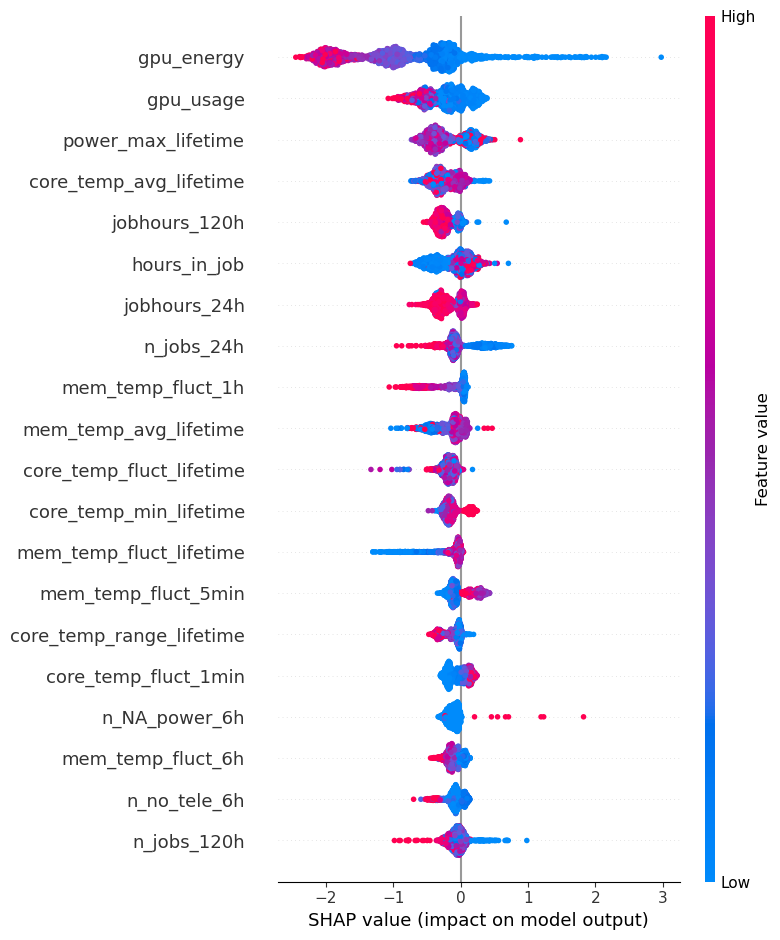

In [56]:
import shap

explainer = shap.TreeExplainer(model)

# Explain a sample instead of all 10k rows
X_shap = X_test_imp[:2000]

shap_values = explainer.shap_values(X_shap)

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=X_train.columns,
    max_display=20
)


In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)

    print(
        f"Threshold {threshold:.2f} | "
        f"Precision: {precision_score(y_test, pred, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_test, pred):.3f} | "
        f"F1: {f1_score(y_test, pred):.3f} | "
        f"Alerts: {pred.sum()}"
    )

Threshold 0.05 | Precision: 0.025 | Recall: 0.759 | F1: 0.047 | Alerts: 1673
Threshold 0.10 | Precision: 0.042 | Recall: 0.630 | F1: 0.078 | Alerts: 818
Threshold 0.15 | Precision: 0.061 | Recall: 0.556 | F1: 0.110 | Alerts: 491
Threshold 0.20 | Precision: 0.087 | Recall: 0.556 | F1: 0.151 | Alerts: 343
Threshold 0.25 | Precision: 0.124 | Recall: 0.556 | F1: 0.203 | Alerts: 242
Threshold 0.30 | Precision: 0.174 | Recall: 0.556 | F1: 0.265 | Alerts: 172
Threshold 0.40 | Precision: 0.208 | Recall: 0.407 | F1: 0.275 | Alerts: 106
Threshold 0.50 | Precision: 0.282 | Recall: 0.370 | F1: 0.320 | Alerts: 71


In [58]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score

anomaly_model = IsolationForest(
    n_estimators=300,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

anomaly_model.fit(X_train_imp)

# Isolation Forest: lower decision score = more anomalous
anomaly_score = -anomaly_model.decision_function(X_test_imp)

print("Anomaly score range:")
print(anomaly_score.min(), "to", anomaly_score.max())

print("\nAnomaly ROC-AUC:",
      roc_auc_score(y_test, anomaly_score))

print("Anomaly PR-AUC:",
      average_precision_score(y_test, anomaly_score))

Anomaly score range:
-0.20581311232766064 to 0.09683300550985774

Anomaly ROC-AUC: 0.445792862276159
Anomaly PR-AUC: 0.00966324694643867


In [59]:
top_features = feature_importance.head(10)["feature"].tolist()

comparison = []

for col in top_features:
    normal_mean = train.loc[train["is_failure"] == 0, col].mean()
    failure_mean = train.loc[train["is_failure"] == 1, col].mean()

    comparison.append({
        "feature": col,
        "normal_mean": normal_mean,
        "failure_mean": failure_mean,
        "difference_%": (
            (failure_mean - normal_mean) /
            (abs(normal_mean) + 1e-9) * 100
        )
    })

pd.DataFrame(comparison).sort_values(
    "difference_%",
    key=abs,
    ascending=False
)

,feature,normal_mean,failure_mean,difference_%
9,n_NA_power_1h,7.804882e+01,2.763444e+02,254.066097
0,n_NA_power_6h,4.653690e+02,1.182133e+03,154.020532
5,gpu_energy,1.492151e+07,6.400728e+06,-57.104011
6,power_max_1min,9.825178e+01,1.320950e+02,34.445407
7,power_range_15min,9.040138e+01,1.210240e+02,33.874109
4,mem_temp_max_5min,3.378273e+01,3.658394e+01,8.291835
3,core_temp_max_5min,3.468179e+01,3.633099e+01,4.755226
1,core_temp_max_15min,3.524472e+01,3.687324e+01,4.620616
2,mem_temp_mean_5min,3.185201e+01,3.329761e+01,4.538477
8,mem_temp_min_1h,2.833116e+01,2.875524e+01,1.496899


In [60]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(model, "models/xgb_gpu_failure_model.pkl")
joblib.dump(imputer, "models/median_imputer.pkl")

print("Models saved successfully.")

Models saved successfully.


In [61]:
print(os.path.getsize("models/xgb_gpu_failure_model.pkl") / 1024 / 1024, "MB")
print(os.path.getsize("models/median_imputer.pkl") / 1024, "KB")

0.5917930603027344 MB
4.6708984375 KB


In [5]:
%pip install mlflow

Note: you may need to restart the kernel to use updated packages.


error: externally-managed-environment

× This environment is externally managed
╰─> This Python installation is managed by uv and should not be modified.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


In [24]:
import sys
print(sys.executable)

C:\Users\KARAN\AppData\Roaming\uv\python\cpython-3.11-windows-x86_64-none\python.exe


In [2]:
import mlflow
import mlflow.xgboost

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("GPU_Failure_Detection")

print("MLflow connected")

KeyboardInterrupt: 